<a href="https://colab.research.google.com/github/hanviol/ev-spare-parts-import-prioritization/blob/main/Azarya_Melkamu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EV Spare-Parts Import Prioritization

**Goal:** recommend which EV replacement parts a new importer in Ethiopia should stock first.

This notebook is the reproducible part of the project:

1. Load the raw data from a pinned GitHub release and verify it
2. Clean the EV listings from five Ethiopian marketplaces
3. Measure each EV model's market presence
4. Select three vehicles with an explainable score
5. *(next)* Parts analysis and the five recommended parts

> Listing counts measure how visible a model is on marketplaces. They are **not** sales or registrations.

## 0. Setup

In [1]:
import hashlib
import io
import os
import re

import matplotlib.pyplot as plt
import pandas as pd
import requests

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

REPO = "hanviol/ev-spare-parts-import-prioritization"
RAW_TAG = "raw-vehicles-2026-11-18"   # pinned release = frozen raw data
RELEASE_URL = f"https://github.com/{REPO}/releases/download/{RAW_TAG}/"

OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 1. Data collection (optional)

The raw data was collected on **2026-11-18** with the scrapers in [`collect/`](https://github.com/hanviol/ev-spare-parts-import-prioritization/tree/main/collect)
and published as the release [`raw-vehicles-2026-11-18`](https://github.com/hanviol/ev-spare-parts-import-prioritization/releases/tag/raw-vehicles-2026-11-18).

| Source | Method | What was collected |
|---|---|---|
| Adey Market | HTML model pages | Listing cards from 24 EV model pages (Telegram channels, dealer sites, TikTok) |
| Jiji Ethiopia | JSON listing endpoint | 13 model searches + the "Electric" filter |
| AfroMekina | JSON filter endpoint | All electric listings |
| Mekina.net | JSON search endpoint | All electric listings |
| Gezat | HTML cards | All electric listings |
| Engocha | – | Blocked (HTTP 403), recorded in the source log |

The scrapers check robots.txt, wait 1.5 s between requests and remove phone numbers, emails and seller names.

Websites change every day, so the analysis below always starts from the frozen release.
Set `COLLECT_FRESH = True` only to collect a new snapshot (the results will differ).

In [2]:
COLLECT_FRESH = False

if COLLECT_FRESH:
    !git clone -q https://github.com/{REPO}.git repo
    !pip install -q -r repo/requirements.txt
    !cd repo && python collect/run_all.py

## 2. Load the raw data

Each file is downloaded from the release and its SHA-256 fingerprint is compared with `checksums.txt`.
If a file was changed after publishing, the notebook stops.

In [3]:
def download(name):
    response = requests.get(RELEASE_URL + name, timeout=300)
    response.raise_for_status()
    return response.content


expected = {}
for line in download("checksums.txt").decode("utf-8").strip().splitlines():
    digest, name = line.split("  ")
    expected[name] = digest

RAW_FILES = [
    "listings_adey.csv",
    "adey_page_summary.csv",
    "listings_jiji.csv",
    "listings_afromekina.csv",
    "listings_mekina.csv",
    "listings_gezat.csv",
    "source_log.csv",
]

raw = {}
for name in RAW_FILES:
    content = download(name)
    if hashlib.sha256(content).hexdigest() != expected[name]:
        raise ValueError(f"{name} does not match its checksum")
    raw[name] = pd.read_csv(io.BytesIO(content))
    print(f"{name:<26} {len(raw[name]):>6} rows   checksum OK")

adey = raw["listings_adey.csv"]
adey_pages = raw["adey_page_summary.csv"]
jiji = raw["listings_jiji.csv"]
afro = raw["listings_afromekina.csv"]
mekina = raw["listings_mekina.csv"]
gezat = raw["listings_gezat.csv"]
source_log = raw["source_log.csv"]

listings_adey.csv            8366 rows   checksum OK


adey_page_summary.csv          28 rows   checksum OK


listings_jiji.csv            3787 rows   checksum OK


listings_afromekina.csv       425 rows   checksum OK


listings_mekina.csv            58 rows   checksum OK


listings_gezat.csv             26 rows   checksum OK


source_log.csv                568 rows   checksum OK


### Source log

Every request made by the scrapers. Jiji's 404s are the "page after the last page" of each search
(every search still returned all its ads). Engocha blocked the scraper (403), so it is not used.

In [4]:
source_log["status"] = source_log["status"].astype(str)
source_log.groupby(["source", "status"]).size().unstack(fill_value=0)

status,200,403,404
source,,,
adey,365,0,0
afromekina,18,0,0
engocha,0,1,0
gezat,2,0,0
jiji,167,0,13
mekina,2,0,0


## 3. Cleaning

All five sources are turned into one table with the same columns:

| Column | Meaning |
|---|---|
| `source` | Marketplace |
| `listing_id` | ID on that marketplace |
| `title` | Listing title (used to identify the model) |
| `model` | Standard model name, e.g. `BYD Yuan Up` |
| `price_etb` | Price in Ethiopian birr (missing if "on request" or implausible) |
| `year` | Model year |
| `mileage_km` | Mileage (not shown on Adey) |
| `seller` | Seller name or account ID (used only to count unique sellers) |

### 3.1 Standard model names

The same car is written many ways: `Volkswagen ID6 Crozz Pro`, `V.W Id.6`, `BYD SEGULL`, `byd_yuan_plus`.
Titles are simplified (lower case, punctuation removed) and checked against a list of patterns.
**Order matters:** specific names come first, e.g. `yuan up` before `yuan`, `bz3x` before `bz3`.

Listings that say **DM-i, DM-p, PHEV, plug-in or hybrid** are plug-in hybrids, not EVs, and are removed later.

In [5]:
MODEL_PATTERNS = [
    ("BYD Seagull", r"sea ?gull|segull|seagul|dolphin mini|atto ?1\b"),
    ("BYD Yuan Up", r"yuan ?up|atto ?2\b"),
    ("BYD Yuan Plus", r"yuan ?plus|yuan ?pluse|yuan ?blus|atto ?3\b"),
    ("BYD e2", r"\be2\b"),
    ("BYD Dolphin", r"dolphin"),
    ("BYD Sealion", r"sea ?lion"),
    ("BYD Seal", r"\bseal\b"),
    ("BYD Song Plus", r"song ?plus|song ?pluse"),
    ("BYD Song L", r"song ?l\b"),
    ("BYD Tang", r"\btang\b"),
    ("BYD Qin Plus", r"\bqin\b"),
    ("BYD Leopard 3", r"(leopard|lepard) ?0?3\b"),
    ("BYD Leopard 5/7/8", r"(leopard|lepard) ?0?[578]\b|titanium"),
    ("Toyota bZ4X", r"bz ?4 ?x"),
    ("Toyota bZ3X", r"bz ?3 ?x"),
    ("Toyota bZ3", r"bz ?3\b"),
    ("Toyota bZ5", r"bz ?5\b"),
    ("VW ID.4", r"\bid ?4\b"),
    ("VW ID.6", r"\bid ?6\b"),
    ("VW ID.3", r"\bid ?3\b"),
    ("VW ID. UNYX", r"unyx"),
    ("Changan Benben E-Star", r"e ?star|ben ?ben"),
    ("Changan Q05", r"\bq ?05\b|nevo"),
    ("Changan Deepal", r"deepal"),
    ("Dongfeng Nammi", r"nammi|nami ?01"),
    ("GAC Aion Y", r"aion"),
    ("Leapmotor T03", r"leap ?motor|\bt ?03\b"),
    ("Neta U", r"neta ?u\b"),
    ("Neta Aya", r"neta ?aya|\baya\b"),
    ("BMW iX3", r"\bix ?3\b"),
    ("Tesla Model Y", r"tesla|model ?y\b"),
]

ALWAYS_HYBRID = ["BYD Leopard 5/7/8"]   # these are only sold as plug-in hybrids
HYBRID_WORDS = r"dm ?i\b|\bdmi\b|dm ?p\b|phev|plug ?in|hybrid"


def simplify(text):
    text = str(text).lower()
    text = re.sub(r"[_\-./()|,]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def find_model(text):
    text = simplify(text)
    for model, pattern in MODEL_PATTERNS:
        if re.search(pattern, text):
            return model
    return None


def is_hybrid(text):
    return bool(re.search(HYBRID_WORDS, simplify(text)))


examples = ["Volkswagen ID6 Crozz Pro", "V.W Id.6 Crozz 2022", "BYD SEGULL", "byd_yuan_plus call",
            "New BYD Song Plus DM-i 2025", "2022/11 Toyota Bz4x 4WD ULTRA", "Toyota bZ3X 2025"]
for example in examples:
    print(f"{example:<32} -> {str(find_model(example)):<16} hybrid={is_hybrid(example)}")

Volkswagen ID6 Crozz Pro         -> VW ID.6          hybrid=False
V.W Id.6 Crozz 2022              -> VW ID.6          hybrid=False
BYD SEGULL                       -> BYD Seagull      hybrid=False
byd_yuan_plus call               -> BYD Yuan Plus    hybrid=False
New BYD Song Plus DM-i 2025      -> BYD Song Plus    hybrid=True
2022/11 Toyota Bz4x 4WD ULTRA    -> Toyota bZ4X      hybrid=False
Toyota bZ3X 2025                 -> Toyota bZ3X      hybrid=False


### 3.2 Prices, years and posting dates

* **Price:** digits only. Values below 1,000,000 ETB or above 30,000,000 ETB are treated as missing
  (they are deposits, monthly payments or typos such as `72` or `52,000,003`; about 1% of prices).
* **Year:** a four-digit year between 2015 and 2026 found in the year field or the title.
* **Posted:** Adey shows relative times (`6d ago`), converted to days before the collection date.

In [6]:
MIN_PRICE = 1_000_000
MAX_PRICE = 30_000_000


def to_number(value):
    if pd.isna(value):
        return None
    digits = re.sub(r"[^0-9.]", "", str(value))
    if digits in ("", "."):
        return None
    return float(digits)


def clean_price(value):
    price = to_number(value)
    if price is None or price < MIN_PRICE or price > MAX_PRICE:
        return None
    return price


def find_year(value):
    match = re.search(r"\b(20[12][0-9])\b", str(value))
    if match is None:
        return None
    year = int(match.group(1))
    if 2015 <= year <= 2026:
        return year
    return None


def days_ago(text):
    match = re.match(r"(\d+)\s*(m|h|d)\b", str(text))
    if match is None:
        return None
    number, unit = int(match.group(1)), match.group(2)
    if unit == "d":
        return number
    return 0   # minutes or hours ago = today


print(clean_price("4,300,000"), clean_price("72"), find_year("2025/12 BYD SEALION 06"), days_ago("6d ago"))

4300000.0 None 2025 6


### 3.3 Put every source into the same format

* **Adey:** the model comes from the title. If the title names no model, the Adey page it was found on is used.
  The title wins because Adey's pages are not always right: its "ID.4 Crozz" page is mostly **ID.6** cars.
  Pages that mix several models (bZ series, ID.4 Crozz, Leopard) become "unspecified" when the title is unclear.
* **Jiji:** the same advert appears under several searches, so duplicates are dropped by `listing_id` first.
  Jiji's search is fuzzy, so the model is always taken from the title, not from the search term.
* **AfroMekina, Mekina, Gezat:** make + model + title are combined, then matched the same way.

In [7]:
ADEY_PAGE_MODEL = {
    "BYD Seagull": "BYD Seagull",
    "BYD Yuan Up": "BYD Yuan Up",
    "BYD Yuan Plus": "BYD Yuan Plus",
    "BYD Sealion": "BYD Sealion",
    "BYD Song Plus": "BYD Song Plus",
    "BYD Tang": "BYD Tang",
    "BYD Qin Plus": "BYD Qin Plus",
    "BYD Seal": "BYD Seal",
    "Changan Benben E-Star": "Changan Benben E-Star",
    "Changan Deepal": "Changan Deepal",
    "VW ID.4": "VW ID.4",
    "VW ID.6": "VW ID.6",
    "Dongfeng Nammi": "Dongfeng Nammi",
    "GAC Aion Y": "GAC Aion Y",
    "Leapmotor T03": "Leapmotor T03",
    "Neta U": "Neta U",
    "Neta Aya": "Neta Aya",
    "BMW iX3": "BMW iX3",
    "Tesla Model Y": "Tesla Model Y",
    # pages that mix models
    "Toyota bZ series": "Toyota bZ (unspecified)",
    "VW ID.4 Crozz": "VW ID (unspecified)",
    "BYD Leopard": "BYD Leopard (unspecified)",
    "BYD Yuan": "BYD (unspecified)",
    "BYD Song": "BYD Song (unspecified)",
}


def adey_model(row):
    model = find_model(row["title"])
    if model is None:
        model = ADEY_PAGE_MODEL.get(row["model_label"])
    return model


adey_clean = pd.DataFrame({
    "source": "Adey",
    "listing_id": adey["listing_id"].astype(str),
    "title": adey["title"],
    "model": adey.apply(adey_model, axis=1),
    "price_etb": adey["price_text"].apply(clean_price),
    "year": adey["title"].apply(find_year),
    "mileage_km": None,
    "seller": adey["seller"],
    "days_since_posted": adey["posted_text"].apply(days_ago),
})

jiji_unique = jiji.drop_duplicates("listing_id")
print(f"Jiji: {len(jiji)} rows -> {len(jiji_unique)} unique adverts (same ad found by several searches)")

jiji_clean = pd.DataFrame({
    "source": "Jiji",
    "listing_id": jiji_unique["listing_id"].astype(str),
    "title": jiji_unique["title"],
    "model": jiji_unique["title"].apply(find_model),
    "price_etb": jiji_unique["price_value"].apply(clean_price),
    "year": jiji_unique["title"].apply(find_year),
    "mileage_km": jiji_unique["mileage_km"],
    "seller": jiji_unique["seller_account_id"].astype(str),
})

afro_text = afro["make"].fillna("") + " " + afro["model"].fillna("") + " " + afro["title"].fillna("")
afro_clean = pd.DataFrame({
    "source": "AfroMekina",
    "listing_id": afro["listing_id"].astype(str),
    "title": afro_text,
    "model": afro_text.apply(find_model),
    "price_etb": afro["price_value"].apply(clean_price),
    "year": afro["year"].apply(find_year),
    "mileage_km": afro["mileage_km"],
    "seller": afro["seller_account_id"].astype(str),
})

mekina_text = mekina["make"].fillna("") + " " + mekina["model"].fillna("") + " " + mekina["title"].fillna("")
mekina_clean = pd.DataFrame({
    "source": "Mekina",
    "listing_id": mekina["listing_id"].astype(str),
    "title": mekina_text,
    "model": mekina_text.apply(find_model),
    "price_etb": mekina["price_value"].apply(clean_price),
    "year": mekina["year"].apply(find_year),
    "mileage_km": mekina["mileage_km"],
    "seller": None,
})

gezat_text = gezat["make"].fillna("") + " " + gezat["model"].fillna("") + " " + gezat["year"].astype(str) + " " + gezat["mileage_text"].fillna("")
gezat_clean = pd.DataFrame({
    "source": "Gezat",
    "listing_id": gezat["listing_id"].astype(str),
    "title": gezat_text,
    "model": gezat_text.apply(find_model),
    "price_etb": gezat["price_text"].apply(clean_price),
    "year": gezat["year"].apply(find_year),
    "mileage_km": gezat["mileage_text"].apply(to_number),
    "seller": None,
})

listings = pd.concat([adey_clean, jiji_clean, afro_clean, mekina_clean, gezat_clean], ignore_index=True)
listings["model"] = listings["model"].fillna("Other EV")
for column in ["price_etb", "year", "mileage_km", "days_since_posted"]:
    listings[column] = pd.to_numeric(listings[column], errors="coerce")

print("Rows after combining:", len(listings))
listings.groupby("source").size().rename("rows")

Jiji: 3787 rows -> 3149 unique adverts (same ad found by several searches)
Rows after combining: 12024


source
Adey          8366
AfroMekina     425
Gezat           26
Jiji          3149
Mekina          58
Name: rows, dtype: int64

### 3.4 Remove plug-in hybrids

Some Adey pages (Seal, Qin Plus, Leopard, Song, Tang, Sealion) mix EV and plug-in hybrid versions.
A listing is removed if its title mentions a hybrid version, or if the model is only sold as a hybrid.

In [8]:
listings["hybrid"] = listings["title"].apply(is_hybrid) | listings["model"].isin(ALWAYS_HYBRID)

hybrids = listings[listings["hybrid"]]
print("Plug-in hybrid listings removed:", len(hybrids))
print(hybrids.groupby("model").size().sort_values(ascending=False).head(8).to_string())

listings = listings[~listings["hybrid"]].drop(columns="hybrid").copy()

Plug-in hybrid listings removed: 1113
model
BYD Leopard 5/7/8    374
BYD Sealion          217
BYD Qin Plus         180
BYD Song Plus        141
BYD Tang             109
BYD Seal              53
BYD Song L            26
Other EV               8


### 3.5 Remove duplicates

**Adey and Gezat:** dealers post the same car to several Telegram channels, and Gezat repeats the same cards.
A listing is a duplicate if another listing on the **same source** has the **same model, same price and same
(simplified) title**. Listings without a price are kept, because there is nothing to compare.

**Jiji, AfroMekina, Mekina:** every advert has its own ID and the titles are generated by the site
(e.g. `Toyota bZ4X 2023 Gray`), so two different cars can share a title and price. Here only repeated IDs are
removed (Jiji adverts found by several searches, done in 3.3).

**Across sources:** the same car can appear on Adey and on AfroMekina. These are *not* merged
(there is no shared ID). Instead, section 4 compares each model's **share within each source**, so a car listed
on two platforms does not inflate one model more than another.

In [9]:
FREE_TEXT_SOURCES = ["Adey", "Gezat"]

listings["title_key"] = listings["title"].apply(simplify)
same_car = listings.duplicated(subset=["source", "model", "price_etb", "title_key"], keep="first")
is_duplicate = same_car & listings["price_etb"].notna() & listings["source"].isin(FREE_TEXT_SOURCES)

before = listings.groupby("source").size()
listings = listings[~is_duplicate].drop(columns="title_key").copy()
after = listings.groupby("source").size()

pd.DataFrame({"before": before, "duplicates removed": before - after, "after": after})

,before,duplicates removed,after
source,,,
Adey,7443,1917,5526
AfroMekina,425,0,425
Gezat,26,16,10
Jiji,2960,0,2960
Mekina,57,0,57


### 3.6 Missing values

Missing values are kept as missing, never filled with guesses:

* **price:** "Price on request" (common on Adey) or outside the plausible range
* **year:** the title does not state it
* **mileage:** Adey cards never show mileage
* **seller:** Mekina and Gezat do not expose a seller ID

In [10]:
missing = listings[["price_etb", "year", "mileage_km", "seller"]].isna().groupby(listings["source"]).mean()
(missing * 100).round(0).astype(int).astype(str) + " %"

,price_etb,year,mileage_km,seller
source,,,,
Adey,43 %,62 %,100 %,0 %
AfroMekina,0 %,0 %,13 %,0 %
Gezat,0 %,0 %,0 %,100 %
Jiji,1 %,1 %,53 %,0 %
Mekina,5 %,9 %,0 %,100 %


In [11]:
print("Adey listings were posted up to", int(listings["days_since_posted"].max()), "days before collection")

listings.to_csv(f"{OUTPUT_DIR}/cleaned_vehicle_listings.csv", index=False)
print("Saved", len(listings), "cleaned listings ->", f"{OUTPUT_DIR}/cleaned_vehicle_listings.csv")

Adey listings were posted up to 30 days before collection
Saved 8978 cleaned listings -> outputs/cleaned_vehicle_listings.csv


## 4. Vehicle metrics

For every model:

| Metric | How it is calculated |
|---|---|
| `listings_total` | Cleaned listings across all sources |
| `sources_present` | Number of the 5 marketplaces that list the model |
| `share_<source>` | Model's share of that source's EV listings |
| `presence_share` | **Average share across Adey, Jiji and AfroMekina** (the three large sources; Mekina and Gezat are too small) |
| `unique_sellers` | Different sellers / accounts offering the model |
| `share_2023_or_older` | Share of listings (with a known year) from 2023 or earlier: older cars need wear parts sooner |
| `median_price_etb`, `median_mileage_km` | Context |

Averaging shares (instead of adding counts) gives each marketplace an equal vote and avoids double counting
cars listed on several platforms.

In [12]:
MAIN_SOURCES = ["Adey", "Jiji", "AfroMekina"]

counts = listings.groupby(["model", "source"]).size().unstack(fill_value=0)
shares = counts / counts.sum()

vehicles = pd.DataFrame({
    "listings_total": counts.sum(axis=1),
    "sources_present": (counts > 0).sum(axis=1),
    "presence_share": shares[MAIN_SOURCES].mean(axis=1),
})
for source in MAIN_SOURCES:
    vehicles[f"share_{source}"] = shares[source]

has_seller = listings["seller"].notna()
listings.loc[has_seller, "seller_key"] = listings.loc[has_seller, "source"] + ":" + listings.loc[has_seller, "seller"].astype(str)
vehicles["unique_sellers"] = listings.groupby("model")["seller_key"].nunique()

with_year = listings[listings["year"].notna()]
vehicles["listings_with_year"] = with_year.groupby("model").size()
vehicles["share_2023_or_older"] = (with_year["year"] <= 2023).groupby(with_year["model"]).mean()
vehicles["median_year"] = with_year.groupby("model")["year"].median()
vehicles["median_price_etb"] = listings.groupby("model")["price_etb"].median()
vehicles["median_mileage_km"] = listings.groupby("model")["mileage_km"].median()

not_a_model = [model for model in vehicles.index if model == "Other EV" or "unspecified" in model]
vehicles = vehicles.drop(index=not_a_model).sort_values("presence_share", ascending=False)

vehicles.round(3).head(20)

,listings_total,sources_present,presence_share,share_Adey,share_Jiji,share_AfroMekina,unique_sellers,listings_with_year,share_2023_or_older,median_year,median_price_etb,median_mileage_km
model,,,,,,,,,,,,
BYD Yuan Up,1461,5,0.149,0.186,0.124,0.136,432,763,0.009,2025.0,5400000.0,11000.0
BYD Seagull,798,5,0.100,0.093,0.075,0.132,286,481,0.069,2024.0,3850000.0,23000.0
BYD Sealion,938,4,0.090,0.133,0.056,0.080,278,530,0.002,2025.0,7500000.0,3000.0
Toyota bZ4X,825,5,0.089,0.067,0.145,0.056,239,655,0.742,2023.0,5950000.0,20000.0
VW ID.6,736,4,0.089,0.049,0.144,0.073,199,603,0.731,2023.0,7000000.0,23000.0
BYD Song Plus,886,4,0.088,0.097,0.110,0.056,260,529,0.006,2025.0,6650000.0,13000.0
BYD e2,312,5,0.069,0.002,0.079,0.127,152,305,0.010,2025.0,4700000.0,14000.0
VW ID.4,437,3,0.049,0.029,0.089,0.028,151,358,0.902,2022.0,5800000.0,30000.0
BYD Yuan Plus,402,4,0.037,0.050,0.038,0.024,169,234,0.009,2025.0,5900000.0,9000.0


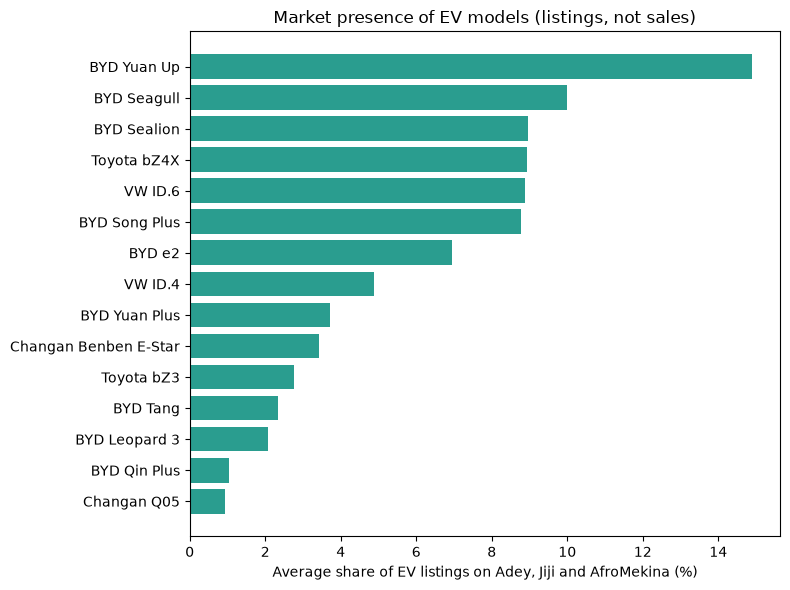

In [13]:
top = vehicles.head(15).sort_values("presence_share")
plt.figure(figsize=(8, 6))
plt.barh(top.index, top["presence_share"] * 100, color="#2a9d8f")
plt.xlabel("Average share of EV listings on Adey, Jiji and AfroMekina (%)")
plt.title("Market presence of EV models (listings, not sales)")
plt.tight_layout()
plt.show()

## 5. Vehicle selection

### 5.1 Gates (pass / fail)

| Gate | Rule | Why |
|---|---|---|
| Pure EV | Plug-in hybrid listings removed in 3.4 | The assignment is about EV parts |
| Market presence | Listed on at least **3 of 5** marketplaces and at least **100** cleaned listings | Enough cars to create parts demand, confirmed by more than one source |
| Candidate list | Final choice comes from the assignment's candidates (ID.4 *or* ID.6 = one slot) | Assignment rule; other models are shown for context |
| Parts data | A parts catalogue exists for the model | **Provisional**, checked in the parts phase |

### 5.2 Criteria, measures and weights

| Criterion | Measure | Becomes a number by | Weight | Why this weight |
|---|---|---|---|---|
| C1 Market presence | `presence_share` | min-max scaled to 0–1 | **40%** | No cars, no parts demand. The most direct evidence we have |
| C2 Fleet maturity | `share_2023_or_older` | min-max scaled to 0–1 | **25%** | Wear parts (pads, discs, shocks) are needed once cars are 2–3 years old |
| C3 After-sales gap | Distributor evidence | 0 = official dealer sells genuine parts, 0.5 = unconfirmed, 1 = grey imports only | **25%** | A new importer competes poorly with an official parts channel |
| C4 Market risk | Import ban history | 1 − risk (ban history = 1) | **10%** | Tie-breaker: a banned model is a risky stock decision |

C3 and C4 are **analyst judgement** based on the evidence below; C1 and C2 come from the data.

**Distributor evidence (C3, C4):**
* BYD: official distributor MOENCO (Inchcape) since Dec 2024, with an after-sales centre and genuine parts
  ([Addis Standard](https://addisstandard.com/chinese-ev-giant-byd-debuts-in-ethiopia-with-five-electric-models-moenco-partnership),
  [Inchcape](https://www.inchcape.com/en/news-and-insights/2024/inchcape-and-byd-partner-again-with-new-distribution-agreement-for-ethiopia))
* Volkswagen ID series: China-built grey imports; imports were banned at VW's request, later lifted
  ([Addis Fortune](https://addisfortune.news/fed-lifts-chinese-assembled-volkswagen-embargo),
  [The Reporter](https://www.thereporterethiopia.com/35052/))
* Changan: first official showroom opened; parts network not confirmed
  ([source](https://africanmarketingconfederation.org/changan-auto-brand-enters-ethiopian-market-with-first-dealership/))
* Toyota bZ: sold by dealers; no official EV parts channel could be confirmed

In [14]:
CANDIDATES = ["BYD Seagull", "BYD Yuan Up", "Changan Benben E-Star", "Toyota bZ4X", "VW ID.4", "VW ID.6"]

AFTER_SALES_GAP = {"BYD": 0.0, "Toyota": 0.5, "Changan": 0.5, "VW": 1.0}   # other brands: 0.5
IMPORT_BAN_HISTORY = {"VW": 1}                                                # other brands: 0

MIN_SOURCES = 3
MIN_LISTINGS = 100

vehicles["passes_gates"] = (vehicles["sources_present"] >= MIN_SOURCES) & (vehicles["listings_total"] >= MIN_LISTINGS)
print("Models passing the gates:", vehicles["passes_gates"].sum(), "of", len(vehicles))
print("Failed:", ", ".join(vehicles.index[~vehicles["passes_gates"]]))

Models passing the gates: 14 of 28
Failed: BYD Qin Plus, Changan Q05, Neta U, Dongfeng Nammi, BYD Seal, Tesla Model Y, BYD Song L, Leapmotor T03, GAC Aion Y, BYD Dolphin, Neta Aya, Changan Deepal, VW ID. UNYX, BMW iX3


In [15]:
def min_max(series):
    return (series - series.min()) / (series.max() - series.min())


def score(table, weights):
    total = 0
    for column, weight in weights.items():
        total = total + table[column] * weight
    return total


ranked = vehicles[vehicles["passes_gates"]].copy()
ranked["brand"] = [model.split()[0] for model in ranked.index]

ranked["c1_presence"] = min_max(ranked["presence_share"])
ranked["c2_maturity"] = min_max(ranked["share_2023_or_older"])
ranked["c3_gap"] = ranked["brand"].map(AFTER_SALES_GAP).fillna(0.5)
ranked["c4_low_risk"] = 1 - ranked["brand"].map(IMPORT_BAN_HISTORY).fillna(0)

WEIGHTS = {"c1_presence": 0.40, "c2_maturity": 0.25, "c3_gap": 0.25, "c4_low_risk": 0.10}

ranked["score"] = score(ranked, WEIGHTS)
ranked["candidate"] = ranked.index.isin(CANDIDATES)
ranked = ranked.sort_values("score", ascending=False)

columns = ["candidate", "presence_share", "share_2023_or_older", "c1_presence", "c2_maturity", "c3_gap", "c4_low_risk", "score"]
ranked[columns].round(3)

,candidate,presence_share,share_2023_or_older,c1_presence,c2_maturity,c3_gap,c4_low_risk,score
model,,,,,,,,
VW ID.6,True,0.089,0.731,0.570,0.811,1.0,0.0,0.681
Toyota bZ4X,True,0.089,0.742,0.575,0.822,0.5,1.0,0.661
VW ID.4,True,0.049,0.902,0.286,1.000,1.0,0.0,0.614
BYD Yuan Up,True,0.149,0.009,1.000,0.010,0.0,1.0,0.503
Changan Benben E-Star,True,0.034,0.662,0.183,0.734,0.5,1.0,0.482
BYD Seagull,True,0.100,0.069,0.651,0.076,0.0,1.0,0.380
Toyota bZ3,False,0.028,0.201,0.134,0.223,0.5,1.0,0.334
BYD Sealion,False,0.090,0.002,0.577,0.002,0.0,1.0,0.331
BYD Song Plus,False,0.088,0.006,0.564,0.006,0.0,1.0,0.327


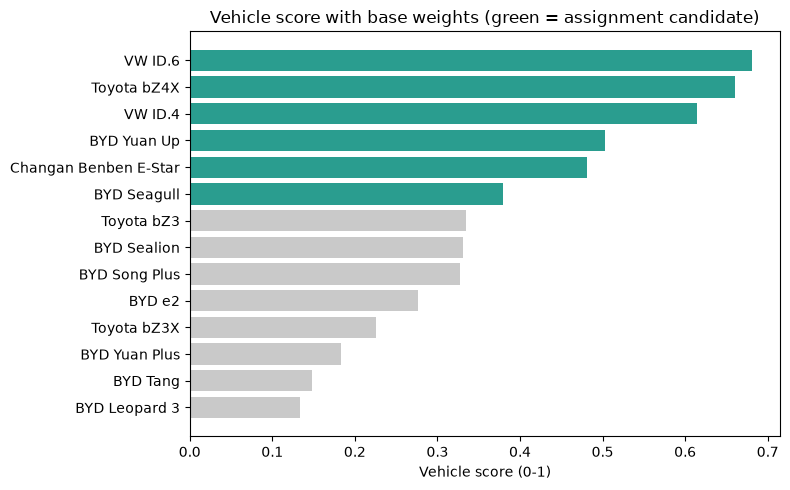

In [16]:
colors = ["#2a9d8f" if is_candidate else "#c9c9c9" for is_candidate in ranked["candidate"]]
plt.figure(figsize=(8, 5))
plt.barh(ranked.index[::-1], ranked["score"][::-1], color=colors[::-1])
plt.xlabel("Vehicle score (0-1)")
plt.title("Vehicle score with base weights (green = assignment candidate)")
plt.tight_layout()
plt.show()

### 5.3 Does changing the weights change the choice?

The same scores are recalculated with different weight sets. `pick_three` takes the three best candidates,
counting ID.4 and ID.6 as one slot.

In [17]:
WEIGHT_SETS = {
    "base (40/25/25/10)": WEIGHTS,
    "equal (25 each)": {"c1_presence": 0.25, "c2_maturity": 0.25, "c3_gap": 0.25, "c4_low_risk": 0.25},
    "presence-heavy": {"c1_presence": 0.60, "c2_maturity": 0.20, "c3_gap": 0.10, "c4_low_risk": 0.10},
    "maturity-heavy": {"c1_presence": 0.30, "c2_maturity": 0.45, "c3_gap": 0.15, "c4_low_risk": 0.10},
    "gap-heavy": {"c1_presence": 0.30, "c2_maturity": 0.20, "c3_gap": 0.40, "c4_low_risk": 0.10},
    "data only (no judgement)": {"c1_presence": 0.60, "c2_maturity": 0.40, "c3_gap": 0.0, "c4_low_risk": 0.0},
}


def pick_three(scores):
    chosen = []
    for model in scores.sort_values(ascending=False).index:
        if model not in CANDIDATES:
            continue
        if model.startswith("VW") and any(m.startswith("VW") for m in chosen):
            continue
        chosen.append(model)
        if len(chosen) == 3:
            break
    return chosen


rows = []
for name, weights in WEIGHT_SETS.items():
    scores = score(ranked, weights)
    rows.append({"weights": name, "selected vehicles": ", ".join(pick_three(scores))})
sensitivity = pd.DataFrame(rows)
sensitivity

,weights,selected vehicles
0,base (40/25/25/10),"VW ID.6, Toyota bZ4X, BYD Yuan Up"
1,equal (25 each),"Toyota bZ4X, Changan Benben E-Star, VW ID.6"
2,presence-heavy,"BYD Yuan Up, Toyota bZ4X, VW ID.6"
3,maturity-heavy,"Toyota bZ4X, VW ID.6, Changan Benben E-Star"
4,gap-heavy,"VW ID.6, Toyota bZ4X, Changan Benben E-Star"
5,data only (no judgement),"Toyota bZ4X, VW ID.6, BYD Yuan Up"


In [18]:
rank_table = pd.DataFrame(index=[m for m in ranked.index if m in CANDIDATES])
for name, weights in WEIGHT_SETS.items():
    candidate_scores = score(ranked, weights)[rank_table.index]
    rank_table[name] = candidate_scores.rank(ascending=False).astype(int)
rank_table

,base (40/25/25/10),equal (25 each),presence-heavy,maturity-heavy,gap-heavy,data only (no judgement)
VW ID.6,1,3,3,2,1,2
Toyota bZ4X,2,1,2,1,3,1
VW ID.4,3,4,5,3,2,4
BYD Yuan Up,4,5,1,5,5,3
Changan Benben E-Star,5,2,6,4,4,6
BYD Seagull,6,6,4,6,6,5


In [19]:
selected = pick_three(ranked["score"])
print("Selected vehicles (base weights):")
for model in selected:
    row = ranked.loc[model]
    print(f"  {model:<14} score {row['score']:.2f} | presence {row['presence_share']:.1%} | "
          f"2023 or older {row['share_2023_or_older']:.0%} | sellers {int(row['unique_sellers'])}")

ranked.to_csv(f"{OUTPUT_DIR}/vehicle_scores.csv")

Selected vehicles (base weights):
  VW ID.6        score 0.68 | presence 8.9% | 2023 or older 73% | sellers 199
  Toyota bZ4X    score 0.66 | presence 8.9% | 2023 or older 74% | sellers 239
  BYD Yuan Up    score 0.50 | presence 14.9% | 2023 or older 1% | sellers 432


### 5.4 Decision

**Selected vehicles: VW ID.6, Toyota bZ4X and BYD Yuan Up.**

* **VW ID.6** and **Toyota bZ4X** are selected under **every** weight set. Each has about 9% of EV listings,
  appears on 4–5 marketplaces with 200+ sellers, and has the oldest fleet: about 3 in 4 listings are from 2023
  or earlier, so wear parts are needed now. The ID.6 also has no official parts channel (grey imports).
* The **third place is close**: BYD Yuan Up wins with 3 weight sets (base, presence-heavy, data only) and
  Changan Benben E-Star with the other 3 (equal, maturity-heavy, gap-heavy). **BYD Yuan Up** is chosen because:
  * it is the most visible EV by a wide margin: 14.9% presence and 432 sellers, against 3.4% and 183 for the Benben E-Star;
  * its fleet is young (mostly 2024–2026), so wear-part demand is still ahead, but collision parts
    (bumpers, lights, mirrors) are needed whatever the car's age;
  * the source pack includes a BYD parts catalogue, while no Benben E-Star catalogue was found.

  The **Benben E-Star is the reserve choice** if the parts phase shows that Yuan Up parts are easy to buy
  through the official BYD dealer.
* **ID.6 instead of ID.4:** the ID.6 has almost twice the presence (8.9% vs 4.9%). Both are built on VW's MEB
  platform, so some parts may fit both; this is checked in the parts phase.
* **Outside the candidate list**, the BYD e2 (6.9% presence, on all 5 marketplaces), Sealion and Song Plus are
  strong but have very young fleets. They are worth watching for a later import round.


### 5.5 What could not be verified

* **Sales and registrations by model:** no public source. Listing shares and unique sellers are proxies.
* **Time window:** Adey shows roughly the last month of posts, so shares describe recent trading activity, not the full vehicle parc.
* **Cross-source duplicates:** the same car can appear on several marketplaces; shares limit, but do not remove, this effect.
* **Gezat:** 26 cards but only 10 distinct cars (the rest repeat under new IDs), some with implausible years (e.g. a 2020 Seagull, a model launched in 2023). Used only to count presence.
* **Model year:** missing in many Adey titles; maturity is based on listings that state a year.
* **After-sales gap:** based on news reports, not on a parts-price survey (checked in the parts phase).
* **Usage intensity:** ride-hailing use (higher wear) could not be measured by model.

## 6. Parts analysis

*Next step:* collect parts evidence (local parts listings, catalogue fitment and prices, failure data)
for the three selected vehicles, then score the parts.